In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd

url = "https://huggingface.co/datasets/liaad/agricultural-data/resolve/main/Crop_recommendation.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
Dataset shape: (2200, 8)


In [11]:
url = "https://huggingface.co/datasets/liaad/agricultural-data/resolve/main/Crop_recommendation.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())

Dataset Shape: (2200, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage:

In [2]:
X = df.drop("label", axis=1)
y = df["label"]

print("Input Features:", X.columns.tolist())
print("Crop Classes:", y.nunique())

Input Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop Classes: 22


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1760
Testing records: 440


In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 97.95 %

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00  

In [8]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy (%)": [
        round(dt_accuracy * 100, 2),
        round(rf_accuracy * 100, 2)
    ]
})

print(results)

           Model  Accuracy (%)
0  Decision Tree         97.95
1  Random Forest         99.55


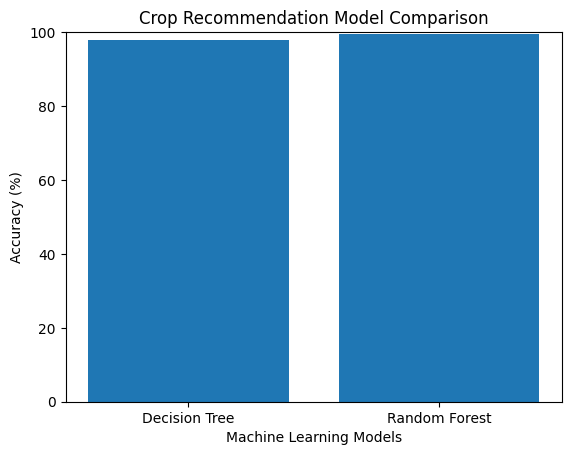

In [9]:
import matplotlib.pyplot as plt

plt.bar(results["Model"], results["Accuracy (%)"])
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Crop Recommendation Model Comparison")
plt.ylim(0, 100)
plt.show()

# sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.88,
    "humidity": 82.0,
    "ph": 6.5,
    "rainfall": 203.0
}])

print("Decision Tree Prediction:", dt_model.predict(sample)[0])
print("Random Forest Prediction:", rf_model.predict(sample)[0])